# 06 · Explainability (SHAP)

**Questions this notebook answers**

1. Which features drive the fraud score overall, and in which direction?
2. How does the score respond to the most important numeric features?
3. Why did the model score three specific transactions the way it did: a caught fraud,
   a missed fraud, and a false alarm?

**Method.** Exact SHAP values from the model itself (TreeSHAP via the booster's native
`pred_contrib` for tree models; coefficient × centred input for logistic regression), so no
approximation and no extra dependency. The explained model is the final pipeline **without the
calibration wrapper**, refit on all dev rows; values are in **log-odds** of that uncalibrated model.
Calibration is monotone, so it does not change the ranking the explanations describe.
One-hot columns are summed back to their source feature. Only dev rows are used.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from fraud_e2e import config as C
from fraud_e2e import plots as P
from fraud_e2e.cv import load_result
from fraud_e2e.data import load_raw
from fraud_e2e.evaluate import fit_final
from fraud_e2e.explain import global_importance, shap_values
from fraud_e2e.features import feature_frame
from fraud_e2e.reporting import read_json, write_csv, write_json
from fraud_e2e.splits import dev_only

P.set_style()
dev = dev_only(load_raw())
final_spec = read_json("p2_modeling")["final_pipeline"]["spec"]
explain_spec = {**final_spec, "calibration": None}
model = fit_final(dev, explain_spec)
phi, base_value = shap_values(model, dev, explain_spec["drop"])

# sanity check: base + sum of SHAP equals the model's log-odds
raw = model.predict_proba(feature_frame(dev, explain_spec["drop"]))[:, 1]
logit = np.log(raw / (1 - raw))
max_err = float(np.abs(base_value + phi.sum(axis=1).to_numpy() - logit).max())
print(f"explained model: {explain_spec['model']}; additivity check max |error| = {max_err:.2e}")

explained model: logreg; additivity check max |error| = 5.33e-15


## 1. Global importance

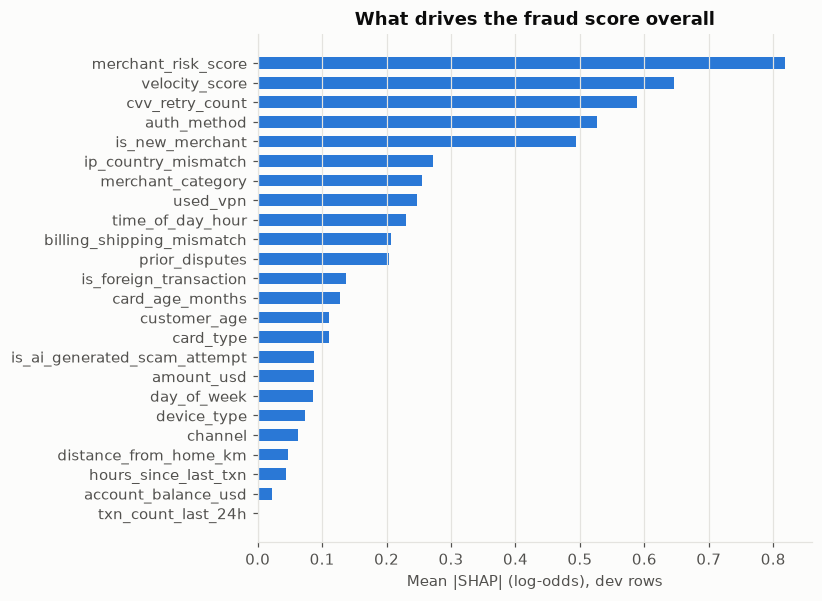

In [2]:
imp = global_importance(phi)
write_csv(imp, "p2_shap_global")

fig, ax = P.plt.subplots(figsize=(6.5, 6))
t = imp.iloc[::-1]
ax.barh(t["feature"], t["mean_abs_shap"], color=P.SERIES[0], height=0.6)
ax.set_xlabel("Mean |SHAP| (log-odds), dev rows")
ax.set_title("What drives the fraud score overall")
ax.grid(axis="y", visible=False)
P.save(fig, "p2_shap_global")
P.plt.show()

## 2. Direction of effects

Each dot is one transaction. Horizontal position is that feature's contribution to the score;
colour is the feature's value (low → high, by rank within the feature). For categorical features
colour is not meaningful and is shown grey.

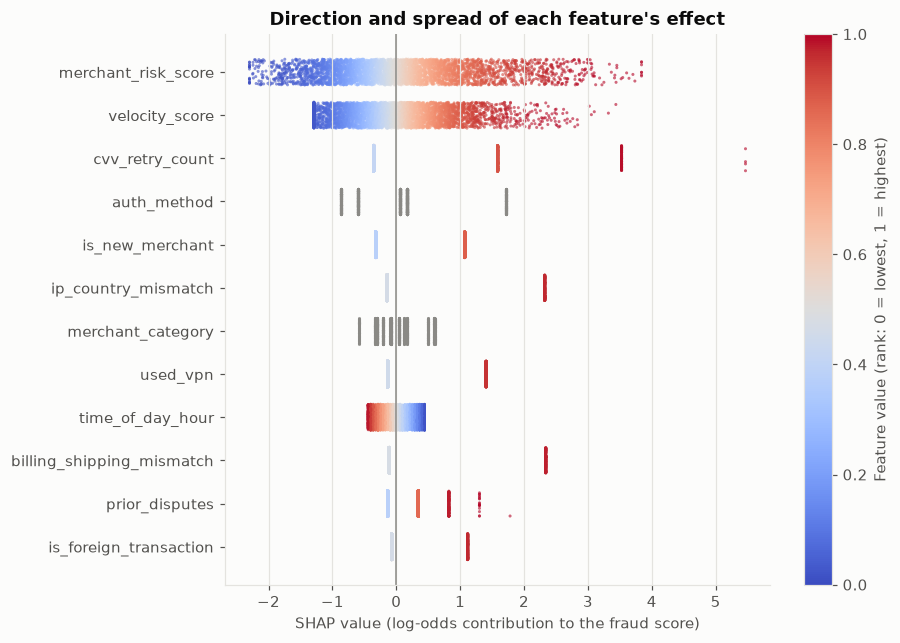

In [3]:
top = imp["feature"].head(12).tolist()
fig, ax = P.plt.subplots(figsize=(8, 6.5))
rng = np.random.default_rng(C.SEED)
sample = rng.choice(len(dev), size=min(4000, len(dev)), replace=False)
fraud_idx = np.flatnonzero(dev[C.TARGET].to_numpy() == 1)
sample = np.unique(np.r_[sample, fraud_idx])  # keep every fraud visible
cmap = P.plt.get_cmap("coolwarm")
for i, f in enumerate(top[::-1]):
    x = phi[f].to_numpy()[sample]
    yj = i + rng.uniform(-0.3, 0.3, len(sample))
    if f in C.CATEGORICAL_COLS:
        ax.scatter(x, yj, s=4, color=P.NEUTRAL, alpha=0.5, lw=0)
    else:
        v = dev[f].astype(float).to_numpy()[sample]
        col = pd.Series(v).rank(pct=True).to_numpy()
        ax.scatter(x, yj, s=4, c=col, cmap=cmap, vmin=0, vmax=1, alpha=0.6, lw=0)
ax.axvline(0, color=P.NEUTRAL, lw=1)
ax.set_yticks(range(len(top)), top[::-1])
ax.set_xlabel("SHAP value (log-odds contribution to the fraud score)")
ax.grid(axis="y", visible=False)
sm = P.plt.cm.ScalarMappable(cmap=cmap, norm=P.plt.Normalize(0, 1))
fig.colorbar(sm, ax=ax, label="Feature value (rank: 0 = lowest, 1 = highest)")
ax.set_title("Direction and spread of each feature's effect")
P.save(fig, "p2_shap_beeswarm")
P.plt.show()

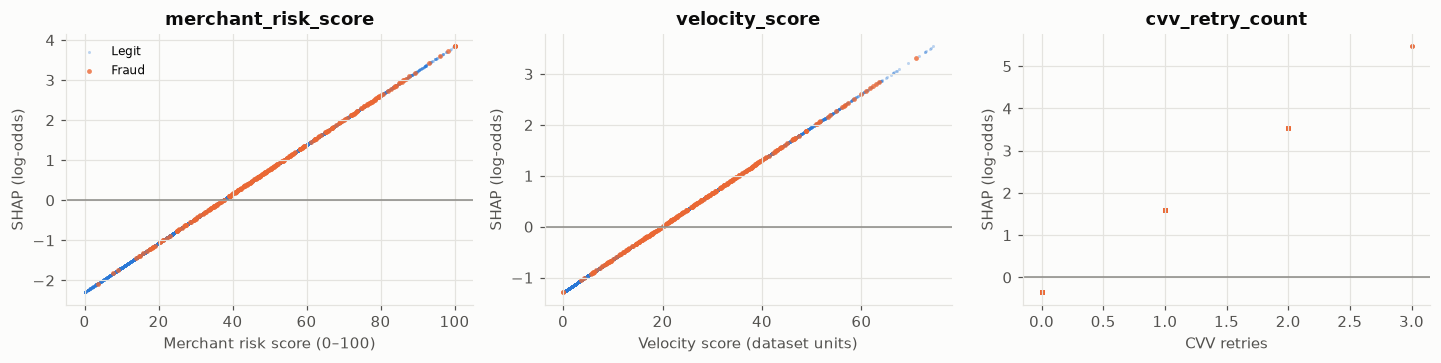

In [4]:
num_top = [f for f in top if f in C.NUMERIC_COLS][:3]
fig, axes = P.plt.subplots(1, len(num_top), figsize=(4.4 * len(num_top), 3.4))
units = {
    "merchant_risk_score": "Merchant risk score (0–100)",
    "cvv_retry_count": "CVV retries",
    "velocity_score": "Velocity score (dataset units)",
    "amount_usd": "Amount (USD)",
    "txn_count_last_24h": "Transactions in last 24 h",
    "hours_since_last_txn": "Hours since previous txn",
    "time_of_day_hour": "Hour of day",
    "customer_age": "Customer age (years)",
    "distance_from_home_km": "Distance from home (km)",
    "account_balance_usd": "Balance (USD)",
    "card_age_months": "Card age (months)",
    "prior_disputes": "Prior disputes",
    "day_of_week": "Day of week (0–6)",
}
for ax, f in zip(np.atleast_1d(axes), num_top):
    y = dev[C.TARGET].to_numpy()
    ax.scatter(
        dev[f].to_numpy()[y == 0],
        phi[f].to_numpy()[y == 0],
        s=4,
        alpha=0.3,
        color=P.LEGIT,
        lw=0,
        label="Legit",
    )
    ax.scatter(
        dev[f].to_numpy()[y == 1],
        phi[f].to_numpy()[y == 1],
        s=10,
        alpha=0.8,
        color=P.FRAUD,
        lw=0,
        label="Fraud",
    )
    ax.axhline(0, color=P.NEUTRAL, lw=1)
    ax.set_xlabel(units.get(f, f))
    ax.set_ylabel("SHAP (log-odds)")
    ax.set_title(f)
np.atleast_1d(axes)[0].legend(fontsize=8)
fig.tight_layout()
P.save(fig, "p2_shap_dependence")
P.plt.show()

## 3. Individual transactions

Three dev transactions picked from the final pipeline's **out-of-fold** results at the chosen
step-up threshold (repeat 0), so the outcome category reflects unseen-data behaviour:

- **caught fraud** — the highest-scoring fraud;
- **missed fraud** — the largest-amount fraud below the threshold;
- **false alarm** — the highest-scoring legitimate transaction.

The bars explain the refit (in-sample) model, whose score can differ from the OOF score.

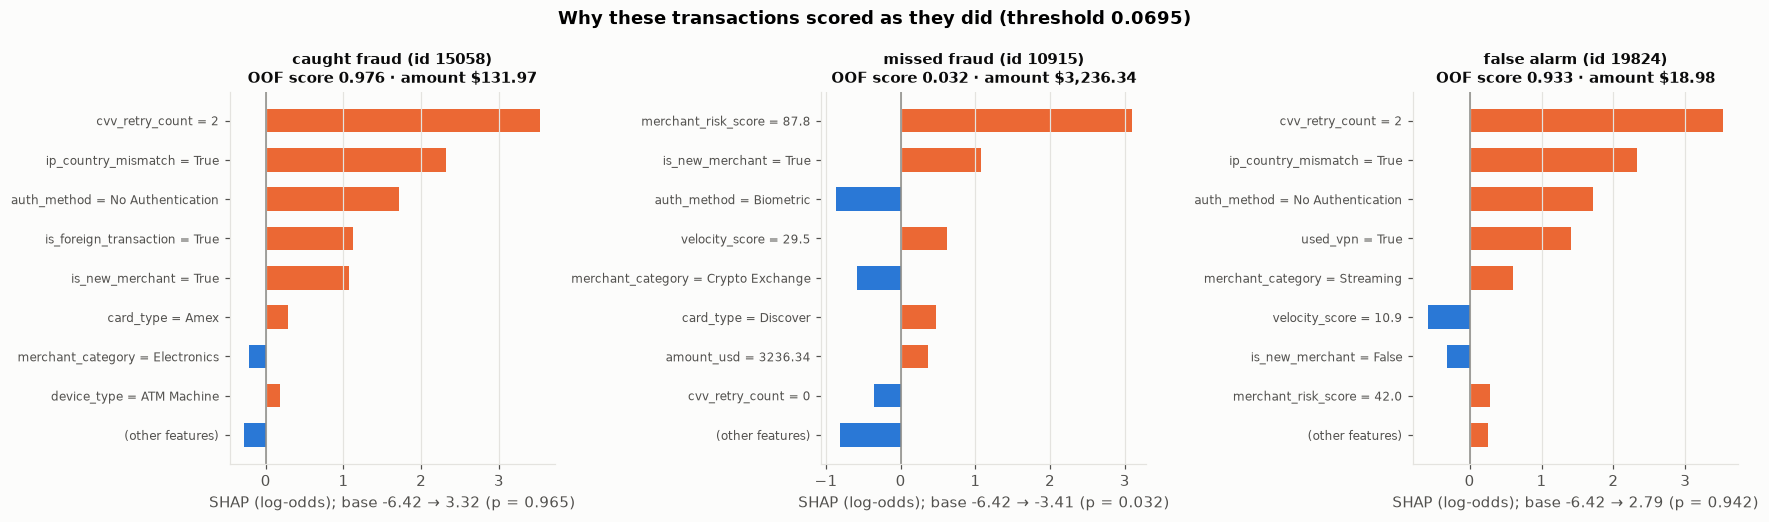

In [5]:
thr = read_json("p2_threshold_web")["chosen_threshold"]
oof0 = load_result("final").oof.query("repeat == 0").set_index(C.ID_COL)
dev_i = dev.set_index(C.ID_COL)
fraud, legit = oof0[oof0["y"] == 1], oof0[oof0["y"] == 0]
picks = {
    "caught fraud": fraud[fraud["score"] >= thr]["score"].idxmax(),
    "missed fraud": fraud[fraud["score"] < thr]["amount_usd"].idxmax(),
    "false alarm": legit["score"].idxmax(),
}

pos = {tid: i for i, tid in enumerate(dev[C.ID_COL])}
examples = []
fig, axes = P.plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (label, tid) in zip(axes, picks.items()):
    contrib = phi.iloc[pos[tid]].sort_values(key=np.abs, ascending=False)
    shown = contrib.head(8)
    rest = contrib.iloc[8:].sum()
    vals = pd.concat([shown, pd.Series({"(other features)": rest})])[::-1]
    names = [f"{k} = {dev_i.loc[tid, k]}" if k in dev_i.columns else k for k in vals.index]
    ax.barh(names, vals.to_numpy(), color=[P.FRAUD if v > 0 else P.LEGIT for v in vals], height=0.6)
    ax.axvline(0, color=P.NEUTRAL, lw=1)
    logit_i = base_value + contrib.sum()
    p_i = 1 / (1 + np.exp(-logit_i))
    ax.set_title(
        f"{label} (id {tid})\nOOF score {oof0.loc[tid, 'score']:.3f} · "
        f"amount ${dev_i.loc[tid, 'amount_usd']:,.2f}",
        fontsize=10,
    )
    ax.set_xlabel(f"SHAP (log-odds); base {base_value:.2f} → {logit_i:.2f} (p = {p_i:.3f})")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
    examples.append(
        {
            "label": label,
            "transaction_id": int(tid),
            "oof_score": float(oof0.loc[tid, "score"]),
            "amount_usd": float(dev_i.loc[tid, "amount_usd"]),
            "is_fraud": int(dev_i.loc[tid, C.TARGET]),
            "base_log_odds": base_value,
            "log_odds": float(logit_i),
            "contributions": [
                {
                    "feature": k,
                    "value": str(dev_i.loc[tid, k]) if k in dev_i else None,
                    "shap": float(v),
                }
                for k, v in contrib.items()
            ],
        }
    )
fig.suptitle(f"Why these transactions scored as they did (threshold {thr:.4f})", fontweight="bold")
fig.tight_layout()
P.save(fig, "p2_shap_examples")
P.plt.show()

In [6]:
write_json(
    {
        "explained_model": explain_spec,
        "base_log_odds": base_value,
        "additivity_max_abs_error": max_err,
        "threshold": thr,
        "global_importance": imp.to_dict(orient="records"),
        "examples": examples,
    },
    "p2_shap",
)

PosixPath('reports/p2_shap.json')

## Summary

In [7]:
top3 = imp.head(3)
share_top3 = top3["mean_abs_shap"].sum() / imp["mean_abs_shap"].sum()
ex = {e["label"]: e for e in examples}


def top_reasons(e, k=3, sign=1):
    c = [x for x in e["contributions"] if np.sign(x["shap"]) == sign][:k]
    return ", ".join(f"`{x['feature']}`" for x in c) or "none"


display(
    Markdown(f"""
- **Top drivers:** {", ".join(f"`{f}`" for f in top3["feature"])} account for
  {100 * share_top3:.0f}% of total mean |SHAP|.
- **Caught fraud** (id {ex["caught fraud"]["transaction_id"]}): pushed up mainly by
  {top_reasons(ex["caught fraud"])}.
- **Missed fraud** (id {ex["missed fraud"]["transaction_id"]}, ${ex["missed fraud"]["amount_usd"]:,.2f}):
  pushed up by {top_reasons(ex["missed fraud"], k=2)} but pulled down by
  {top_reasons(ex["missed fraud"], sign=-1)}; starting from the low base log-odds
  ({base_value:.2f}, fraud is rare) it ended at p = {1 / (1 + np.exp(-ex["missed fraud"]["log_odds"])):.3f},
  below the {thr:.4f} threshold. One strong signal without the other red flags is not enough.
- **False alarm** (id {ex["false alarm"]["transaction_id"]}): pushed up by
  {top_reasons(ex["false alarm"])} — the same red flags as the caught fraud, on a legitimate
  transaction. From these features alone the two are hard to tell apart.
- SHAP values explain the uncalibrated model (additivity error {max_err:.1e}); they describe what
  the model learned from this dataset, not causes of fraud.
""")
)


- **Top drivers:** `merchant_risk_score`, `velocity_score`, `cvv_retry_count` account for
  37% of total mean |SHAP|.
- **Caught fraud** (id 15058): pushed up mainly by
  `cvv_retry_count`, `ip_country_mismatch`, `auth_method`.
- **Missed fraud** (id 10915, $3,236.34):
  pushed up by `merchant_risk_score`, `is_new_merchant` but pulled down by
  `auth_method`, `merchant_category`, `cvv_retry_count`; starting from the low base log-odds
  (-6.42, fraud is rare) it ended at p = 0.032,
  below the 0.0695 threshold. One strong signal without the other red flags is not enough.
- **False alarm** (id 19824): pushed up by
  `cvv_retry_count`, `ip_country_mismatch`, `auth_method` — the same red flags as the caught fraud, on a legitimate
  transaction. From these features alone the two are hard to tell apart.
- SHAP values explain the uncalibrated model (additivity error 5.3e-15); they describe what
  the model learned from this dataset, not causes of fraud.
